# Experiment 027: sweep-end generative hardening analysis

Here I complete three-seed generative coverage for the p2, p8 and p32 base MC-SFT endpoints at 0.5B, 1.5B and 3B.

The registered comparisons are p2 minus p8 and p32 minus p8 within each scale and seed. Exact McNemar tests are Holm-corrected across the three seeds in each scale and exposure family. Paired bootstrap intervals show the effect size.

The exposure curves are method-as-practised comparisons. Every exposure uses its own linear learning-rate schedule, so the figures compare complete training recipes rather than changing only the number of examples seen.


In [1]:
# load the three-scale supervised exposure results
import hashlib
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'config.py').exists():
    raise FileNotFoundError('repository root containing config.py was not found')
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import TIERS as VALIDATED_TIERS

RES = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '027_1'
FIG.mkdir(parents=True, exist_ok=True)

SEEDS = (0, 1, 2)
SCALES = ('0.5B', '1.5B', '3B')
EXPOSURES = ('p2', 'p8', 'p32')
COMPARISON_EXPOSURES = ('p2', 'p32')
PASSES = {'p2': 2, 'p8': 8, 'p32': 32}
TIERS = ('easy', 'medium', 'hard')
GROUPS = TIERS + ('overall',)
TAGS = {
    '0.5B': ('007', 'B05'),
    '1.5B': ('010', 'B15'),
    '3B': ('007', 'B3'),
}
EXPECTED_GPU = {
    '0.5B': 'A100-SXM4-40GB',
    '1.5B': 'A100-SXM4-80GB',
    '3B': 'A100-SXM4-40GB',
}
COLORS = {
    'p2': '#4C78A8',
    'p8': '#F58518',
    'p32': '#E45756',
}
SCALE_COLORS = {
    '0.5B': '#4C78A8',
    '1.5B': '#F58518',
    '3B': '#54A24B',
}
TIER_LOOKUP = {
    subject: tier
    for tier, subjects in VALIDATED_TIERS.items()
    for subject in subjects
}
SUBJECTS = [
    subject
    for tier in TIERS
    for subject in VALIDATED_TIERS[tier]
]

PATHS = {
    scale: {
        exposure: {
            seed: RES / f'{prefix}_{exposure}_COLAB_FULL_{scale_code}_sft_only_seed{seed}'
            for seed in SEEDS
        }
        for exposure in EXPOSURES
    }
    for scale, (prefix, scale_code) in TAGS.items()
}

plt.style.use('seaborn-v0_8-whitegrid')

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        rows = [json.loads(line) for line in handle if line.strip()]
    return [
        {**row, 'tier': row.get('tier', TIER_LOOKUP[row['subject']])}
        for row in rows
    ]

def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')
    print('saved', name)

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def nonfinite_paths(value, path='root'):
    found = []
    if isinstance(value, dict):
        for key, item in value.items():
            found.extend(nonfinite_paths(item, f'{path}/{key}'))
    elif isinstance(value, list):
        for index, item in enumerate(value):
            found.extend(nonfinite_paths(item, f'{path}/{index}'))
    elif isinstance(value, float) and not math.isfinite(value):
        found.append(path)
    return found

def load_run(path):
    manifest_path = path / 'sft_eval_manifest.json'
    return {
        'path': path,
        'summary': jload(path / 'summary.json'),
        'eval': jload(path / 'sft_eval.json'),
        'probe': jload(path / 'sft_logprob.json'),
        'preds': jsonl(path / 'sft_preds.jsonl'),
        'probe_preds': jsonl(path / 'sft_logprob_preds.jsonl'),
        'eval_manifest': jload(manifest_path) if manifest_path.exists() else None,
    }

RUNS = {
    scale: {
        exposure: {
            seed: load_run(path)
            for seed, path in seeds.items()
        }
        for exposure, seeds in exposures.items()
    }
    for scale, exposures in PATHS.items()
}

print('loaded 27 supervised endpoints across three scales')
print('figures ->', FIG.relative_to(ROOT))


loaded 27 supervised endpoints across three scales
figures -> analysis/figures/027_1


## 1. Completion and integrity

The twelve new evaluations are checked before any result is interpreted. The checks cover the transaction manifest, prediction and metric hashes, identity-gate agreement, adapter hashes, item counts, precision and the registered GPU variant.


In [2]:
# verify the twelve new evaluations and all reference endpoints
health_rows = []
for scale in SCALES:
    for exposure in EXPOSURES:
        for seed in SEEDS:
            data = RUNS[scale][exposure][seed]
            assert data['eval']['n_items'] == 1884
            assert data['probe']['n_items'] == 1884
            assert len(data['preds']) == 1884
            assert len(data['probe_preds']) == 1884
            assert not nonfinite_paths(data['eval'])
            assert not nonfinite_paths(data['probe'])
            assert data['summary']['seed'] == seed
            assert data['summary']['sft_acc'] == data['eval']['per_tier_acc']

            if exposure not in COMPARISON_EXPOSURES or seed == 0:
                continue

            manifest = data['eval_manifest']
            assert manifest['package'] == '027_s12'
            assert manifest['completed'] is True
            assert manifest['condition'] == 'sft'
            assert manifest['seed_override'] == seed
            assert manifest['resolved_dtype'] == 'bfloat16'
            assert EXPECTED_GPU[scale] in manifest['gpu']['device']
            assert manifest['sha256_preds'] == sha256(data['path'] / 'sft_preds.jsonl')
            assert manifest['sha256_eval'] == sha256(data['path'] / 'sft_eval.json')
            assert manifest['summary_sha_after'] == sha256(data['path'] / 'summary.json')
            assert manifest['gate']['agreement'] >= 0.99
            assert abs(
                manifest['gate']['acc_new'] - manifest['gate']['acc_archived']
            ) <= 0.001
            assert set(manifest['adapter_sha256']) == {
                'adapter_model.safetensors',
                'adapter_config.json',
                'adapter_base.json',
                'config_hash.txt',
            }
            assert all(
                isinstance(value, str) and len(value) == 64
                for value in manifest['adapter_sha256'].values()
            )

            health_rows.append({
                'scale': scale,
                'exposure': exposure,
                'seed': seed,
                'GPU': manifest['gpu']['device'],
                'gate agreement': manifest['gate']['agreement'],
                'probe minutes': manifest['timings_sec']['gate_logprob'] / 60,
                'generative minutes': manifest['timings_sec']['sft_eval'] / 60,
                'format compliance': data['eval']['format_compliance'],
                'extraction failures': data['eval']['extraction_failure_rate'],
                'config hash status': manifest['config_hash_status'],
                'git commit': manifest['git']['commit'][:8],
            })

health_tbl = pd.DataFrame(health_rows).set_index(['scale', 'exposure', 'seed'])
assert len(health_tbl) == 12
display(health_tbl.round(4))
print('all twelve new evaluations passed the registered integrity checks')


GPU  gate agreement  probe minutes  \
scale exposure seed                                                         
0.5B  p2       1     NVIDIA A100-SXM4-40GB             1.0         0.5440   
               2     NVIDIA A100-SXM4-40GB             1.0         0.3337   
      p32      1     NVIDIA A100-SXM4-40GB             1.0         0.3363   
               2     NVIDIA A100-SXM4-40GB             1.0         0.3357   
1.5B  p2       1     NVIDIA A100-SXM4-80GB             1.0         0.6275   
               2     NVIDIA A100-SXM4-80GB             1.0         0.3926   
      p32      1     NVIDIA A100-SXM4-80GB             1.0         0.3888   
               2     NVIDIA A100-SXM4-80GB             1.0         0.3896   
3B    p2       1     NVIDIA A100-SXM4-40GB             1.0         0.8326   
               2     NVIDIA A100-SXM4-40GB             1.0         0.5227   
      p32      1     NVIDIA A100-SXM4-40GB             1.0         0.5298   
               2     NVIDIA A100-SXM4-40GB             1.0         0.5257   

                     generative minutes  format compliance  \
scale exposure seed                                          
0.5B  p2       1                 5.1091             0.7845   
               2                 4.9822             0.7012   
      p32      1                 4.5042             0.9979   
               2                 4.5035             0.9156   
1.5B  p2       1                 5.0720             0.9995   
               2                 5.1758             0.9798   
      p32      1                 5.0012             0.9963   
               2                 5.0735             1.0000   
3B    p2       1                 5.8013             1.0000   
               2                 5.8197             1.0000   
      p32      1                 5.8330             1.0000   
               2                 5.8336             1.0000   

                     extraction failures               config hash status  \
scale exposure seed                                                         
0.5B  p2       1                  0.0021  legacy_missing_sft_from_adapter   
               2                  0.0143  legacy_missing_sft_from_adapter   
      p32      1                  0.0000  legacy_missing_sft_from_adapter   
               2                  0.0000  legacy_missing_sft_from_adapter   
1.5B  p2       1                  0.0000                          current   
               2                  0.0058                          current   
      p32      1                  0.0000                          current   
               2                  0.0000                          current   
3B    p2       1                  0.0000  legacy_missing_sft_from_adapter   
               2                  0.0000  legacy_missing_sft_from_adapter   
      p32      1                  0.0000  legacy_missing_sft_from_adapter   
               2                  0.0000  legacy_missing_sft_from_adapter   

                    git commit  
scale exposure seed             
0.5B  p2       1      0cf513de  
               2      0cf513de  
      p32      1      0cf513de  
               2      0cf513de  
1.5B  p2       1      d0d7aa1f  
               2      d0d7aa1f  
      p32      1      d0d7aa1f  
               2      d0d7aa1f  
3B    p2       1      0cf513de  
               2      0cf513de  
      p32      1      0cf513de  
               2      0cf513de

all twelve new evaluations passed the registered integrity checks


## 2. Three-seed exposure curves

Dots show individual seeds, vertical lines show the seed range and the connected points show the three-seed means. The hard-tier panels help separate changes in the most difficult subjects from the overall average.


saved fig01_three_seed_exposure_curves


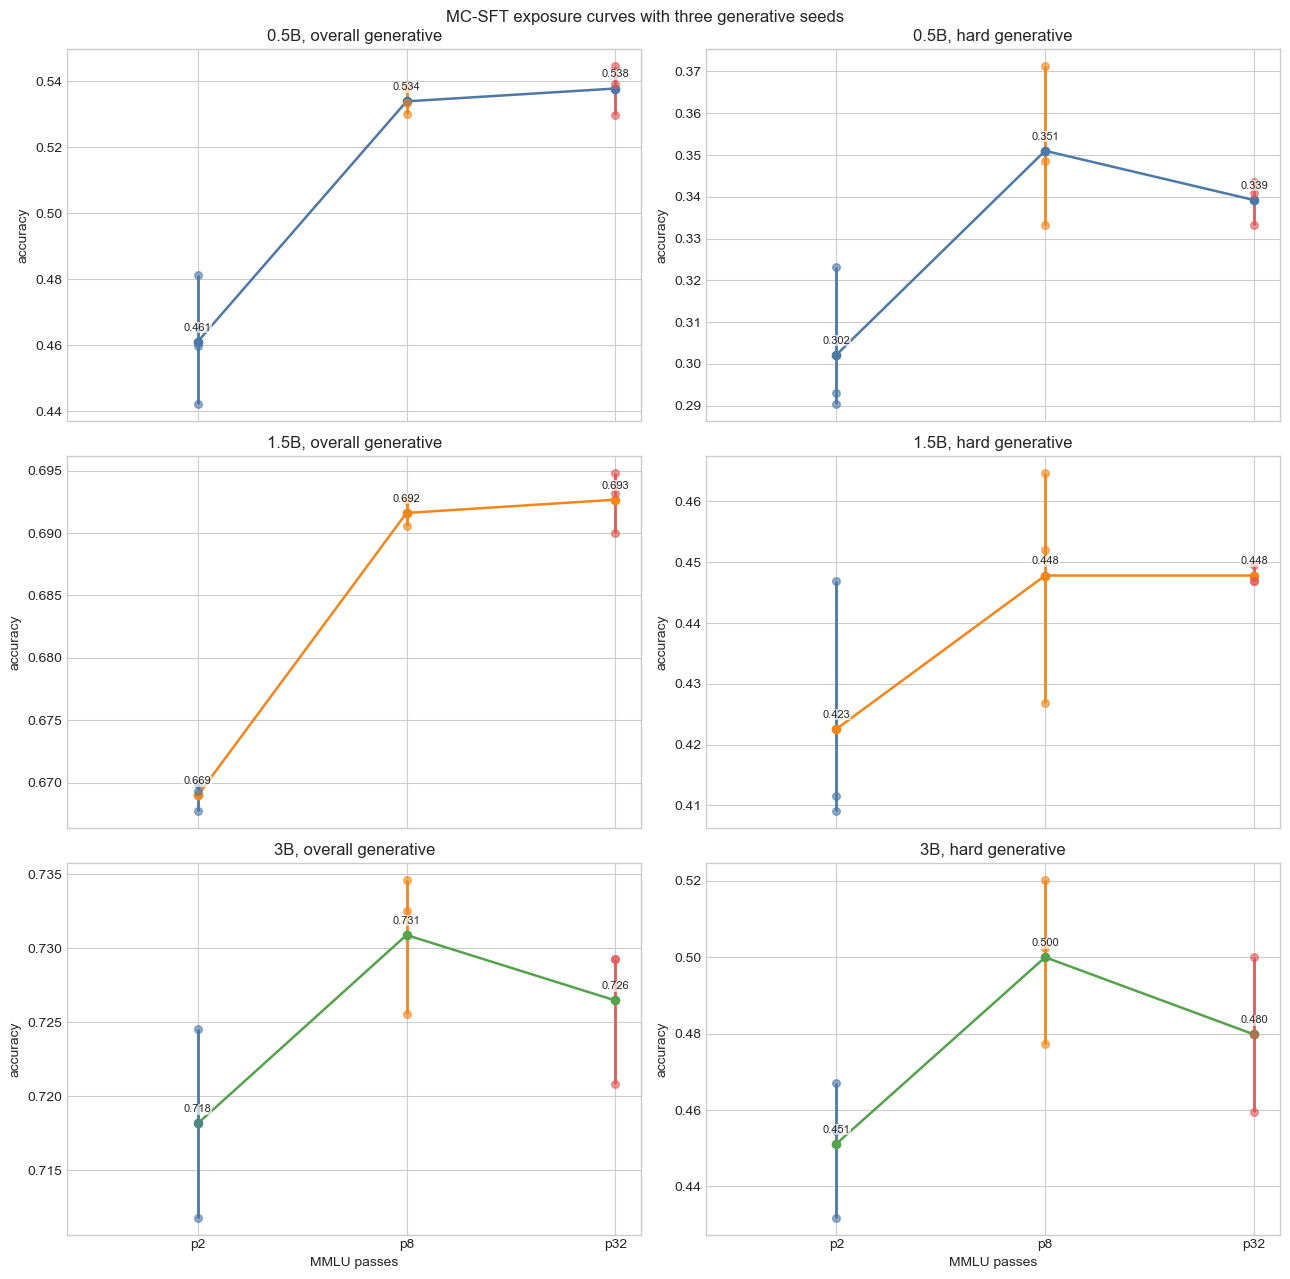

overall generative                 hard generative          \
                             mean     min     max            mean     min   
scale exposure                                                              
0.5B  p2                   0.4611  0.4421  0.4814          0.3022  0.2904   
      p32                  0.5379  0.5297  0.5446          0.3392  0.3333   
      p8                   0.5340  0.5303  0.5382          0.3510  0.3333   
1.5B  p2                   0.6690  0.6677  0.6699          0.4226  0.4091   
      p32                  0.6927  0.6900  0.6948          0.4478  0.4470   
      p8                   0.6916  0.6906  0.6927          0.4478  0.4268   
3B    p2                   0.7182  0.7118  0.7245          0.4512  0.4318   
      p32                  0.7265  0.7208  0.7293          0.4798  0.4596   
      p8                   0.7309  0.7256  0.7346          0.5000  0.4773   

                       overall probe                 hard probe          \
                   max          mean     min     max       mean     min   
scale exposure                                                            
0.5B  p2        0.3232        0.5642  0.5605  0.5685     0.3628  0.3510   
      p32       0.3434        0.5517  0.5488  0.5568     0.3350  0.3207   
      p8        0.3712        0.5563  0.5536  0.5594     0.3535  0.3510   
1.5B  p2        0.4470        0.7003  0.6964  0.7054     0.4335  0.4192   
      p32       0.4495        0.6989  0.6969  0.7012     0.4503  0.4369   
      p8        0.4646        0.6955  0.6932  0.6980     0.4184  0.4116   
3B    p2        0.4672        0.7412  0.7410  0.7415     0.4966  0.4924   
      p32       0.5000        0.7465  0.7436  0.7505     0.5168  0.5000   
      p8        0.5202        0.7475  0.7468  0.7479     0.5143  0.5101   

                        
                   max  
scale exposure          
0.5B  p2        0.3737  
      p32       0.3561  
      p8        0.3561  
1.5B  p2        0.4545  
      p32       0.4596  
      p8        0.4293  
3B    p2        0.5025  
      p32       0.5379  
      p8        0.5202

In [3]:
# build the three-scale endpoint table
endpoint_rows = []
for scale in SCALES:
    for exposure in EXPOSURES:
        for seed in SEEDS:
            data = RUNS[scale][exposure][seed]
            endpoint_rows.append({
                'scale': scale,
                'exposure': exposure,
                'passes': PASSES[exposure],
                'seed': seed,
                'overall generative': accuracy(data['preds']),
                'easy generative': data['eval']['per_tier_acc']['easy'],
                'medium generative': data['eval']['per_tier_acc']['medium'],
                'hard generative': data['eval']['per_tier_acc']['hard'],
                'overall probe': accuracy(data['probe_preds']),
                'hard probe': data['probe']['per_tier_acc']['hard'],
                'hard margin': (
                    data['eval']['per_tier_acc']['hard']
                    - data['probe']['per_tier_acc']['hard']
                ),
                'format compliance': data['eval']['format_compliance'],
            })
endpoint_tbl = pd.DataFrame(endpoint_rows)

fig, axes = plt.subplots(3, 2, figsize=(13, 13), sharex=True)
for row, scale in enumerate(SCALES):
    for col, metric in enumerate(['overall generative', 'hard generative']):
        ax = axes[row, col]
        means = []
        for exposure in EXPOSURES:
            table = endpoint_tbl.query(
                'scale == @scale and exposure == @exposure'
            )
            x = PASSES[exposure]
            values = table[metric].to_numpy()
            means.append(values.mean())
            ax.scatter(
                np.full(len(values), x),
                values,
                color=COLORS[exposure],
                alpha=0.6,
                s=30,
                zorder=3,
            )
            ax.vlines(
                x,
                values.min(),
                values.max(),
                color=COLORS[exposure],
                lw=2,
            )
            ax.annotate(
                f'{values.mean():.3f}',
                xy=(x, values.mean()),
                xytext=(0, 8),
                textcoords='offset points',
                ha='center',
                fontsize=8,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.65, pad=0.4),
            )
        ax.plot(
            [PASSES[value] for value in EXPOSURES],
            means,
            color=SCALE_COLORS[scale],
            marker='o',
            lw=1.8,
        )
        ax.set_xscale('log', base=2)
        ax.set_xticks([2, 8, 32])
        ax.set_xticklabels(['p2', 'p8', 'p32'])
        ax.set_ylabel('accuracy')
        ax.set_title(f'{scale}, {metric}')

for ax in axes[-1]:
    ax.set_xlabel('MMLU passes')
fig.suptitle('MC-SFT exposure curves with three generative seeds')
fig.tight_layout()
save(fig, 'fig01_three_seed_exposure_curves')
plt.show()

display(
    endpoint_tbl.groupby(['scale', 'exposure'])[[
        'overall generative',
        'hard generative',
        'overall probe',
        'hard probe',
    ]].agg(['mean', 'min', 'max']).round(4)
)


## 3. Registered matched comparisons

Each contrast compares predictions for the same 1,884 MMLU items and the same seed. A result is a material improvement or decline only when the absolute change is at least 2 percentage points and the Holm-adjusted McNemar value is below 0.05. Equivalence requires the full paired 95% interval to stay inside the plus or minus 2 point region.


In [4]:
# calculate the registered paired statistics
def paired_metric(reference_rows, new_rows, bootstrap_seed):
    reference_rows, new_rows = align_pred_rows(reference_rows, new_rows)
    reference_correct = np.asarray([
        bool(row['correct']) for row in reference_rows
    ])
    new_correct = np.asarray([
        bool(row['correct']) for row in new_rows
    ])
    delta, low, high = paired_delta_ci(
        reference_correct,
        new_correct,
        seed=bootstrap_seed,
    )
    reference_only = int(np.sum(reference_correct & ~new_correct))
    new_only = int(np.sum(~reference_correct & new_correct))
    return {
        'reference': float(reference_correct.mean()),
        'new': float(new_correct.mean()),
        'delta': delta,
        'ci low': low,
        'ci high': high,
        'p raw': mcnemar_exact(new_only, reference_only),
        'reference only correct': reference_only,
        'new only correct': new_only,
    }

def classify(row):
    if abs(row['delta']) >= 0.02 and row['Holm p'] < 0.05:
        return 'material improvement' if row['delta'] > 0 else 'material decline'
    if row['ci low'] > -0.02 and row['ci high'] < 0.02:
        return 'equivalent'
    return 'inconclusive'

def common_reading(categories):
    decisive = {'equivalent', 'material improvement', 'material decline'}
    if len(set(categories)) == 1 and categories[0] in decisive:
        return categories[0]
    return 'mixed or inconclusive, report arm by arm'

effect_rows = []
for scale_index, scale in enumerate(SCALES):
    for exposure_index, exposure in enumerate(COMPARISON_EXPOSURES):
        family = []
        for seed in SEEDS:
            values = paired_metric(
                RUNS[scale]['p8'][seed]['preds'],
                RUNS[scale][exposure][seed]['preds'],
                27000 + scale_index * 100 + exposure_index * 10 + seed,
            )
            family.append({
                'scale': scale,
                'exposure': exposure,
                'comparison': f'{exposure} minus p8',
                'seed': seed,
                **values,
            })
        adjusted = holm([row['p raw'] for row in family])
        for row, adjusted_p in zip(family, adjusted):
            row['Holm p'] = adjusted_p
            row['classification'] = classify(row)
        effect_rows.extend(family)

effect_tbl = pd.DataFrame(effect_rows)
common_rows = []
for scale in SCALES:
    for exposure in COMPARISON_EXPOSURES:
        categories = (
            effect_tbl.query('scale == @scale and exposure == @exposure')
            .sort_values('seed')['classification']
            .tolist()
        )
        common_rows.append({
            'scale': scale,
            'comparison': f'{exposure} minus p8',
            'common reading': common_reading(categories),
        })
common_tbl = pd.DataFrame(common_rows)

new_evaluations = []
for scale in SCALES:
    for exposure in COMPARISON_EXPOSURES:
        for seed in (1, 2):
            manifest = RUNS[scale][exposure][seed]['eval_manifest']
            new_evaluations.append({
                'scale': scale,
                'exposure': exposure,
                'seed': seed,
                'adapter_sha256': manifest['adapter_sha256'],
                'predictions_sha256': manifest['sha256_preds'],
                'metrics_sha256': manifest['sha256_eval'],
                'identity_agreement': manifest['gate']['agreement'],
            })

endpoint_summary = []
for scale in SCALES:
    for exposure in EXPOSURES:
        table = endpoint_tbl.query(
            'scale == @scale and exposure == @exposure'
        ).sort_values('seed')
        values = table['overall generative'].to_numpy()
        mean = float(values.mean())
        seed_zero = float(table.query('seed == 0')['overall generative'].iloc[0])
        endpoint_summary.append({
            'scale': scale,
            'exposure': exposure,
            'seed_values': {
                str(int(seed)): float(value)
                for seed, value in zip(table['seed'], values)
            },
            'mean': mean,
            'minimum': float(values.min()),
            'maximum': float(values.max()),
            'spread': float(values.max() - values.min()),
            'mean_minus_seed0': mean - seed_zero,
            'material_change_from_seed0': abs(mean - seed_zero) >= 0.02,
        })

comparison_summary = {
    'binding': len(effect_tbl) == 18 and len(new_evaluations) == 12,
    'method_label': 'method-as-practised exposure comparison',
    'thresholds': {
        'material_delta': 0.02,
        'alpha': 0.05,
        'equivalence_margin': 0.02,
        'holm_family': 'three seeds within each scale and exposure',
    },
    'common_readings': {
        scale: {
            exposure: common_tbl.query(
                'scale == @scale and comparison == @comparison'
            )['common reading'].iloc[0]
            for exposure, comparison in [
                ('p2', 'p2 minus p8'),
                ('p32', 'p32 minus p8'),
            ]
        }
        for scale in SCALES
    },
    'comparisons': effect_tbl.to_dict(orient='records'),
    'endpoints': endpoint_summary,
    'new_evaluations': new_evaluations,
}
assert comparison_summary['binding'] is True
with open(RES / '027_comparison_summary.json', 'w') as handle:
    json.dump(comparison_summary, handle, indent=2)

display(effect_tbl.set_index(['scale', 'comparison', 'seed']).round(6))
display(common_tbl.set_index(['scale', 'comparison']))
print('saved results/027_comparison_summary.json')


exposure  reference       new     delta    ci low  \
scale comparison   seed                                                     
0.5B  p2 minus p8  0          p2   0.538217  0.442144 -0.096072 -0.121550   
                   1          p2   0.533439  0.459660 -0.073779 -0.097134   
                   2          p2   0.530255  0.481423 -0.048832 -0.072718   
      p32 minus p8 0         p32   0.538217  0.529724 -0.008493 -0.022293   
                   1         p32   0.533439  0.539278  0.005839 -0.006900   
                   2         p32   0.530255  0.544586  0.014331 -0.001062   
1.5B  p2 minus p8  0          p2   0.691614  0.669851 -0.021762 -0.038217   
                   1          p2   0.690552  0.669321 -0.021231 -0.037686   
                   2          p2   0.692675  0.667728 -0.024947 -0.042463   
      p32 minus p8 0         p32   0.691614  0.694798  0.003185 -0.006369   
                   1         p32   0.690552  0.690021 -0.000531 -0.010085   
                   2         p32   0.692675  0.693206  0.000531 -0.009554   
3B    p2 minus p8  0          p2   0.732484  0.724522 -0.007962 -0.020170   
                   1          p2   0.725584  0.711783 -0.013800 -0.026539   
                   2          p2   0.734607  0.718153 -0.016454 -0.029193   
      p32 minus p8 0         p32   0.732484  0.720807 -0.011677 -0.022824   
                   1         p32   0.725584  0.729299  0.003715 -0.005839   
                   2         p32   0.734607  0.729299 -0.005308 -0.014862   

                          ci high     p raw  reference only correct  \
scale comparison   seed                                               
0.5B  p2 minus p8  0    -0.071125  0.000000                     392   
                   1    -0.050425  0.000000                     329   
                   2    -0.024947  0.000095                     319   
      p32 minus p8 0     0.005308  0.268760                     100   
                   1     0.018577  0.412743                      69   
                   2     0.029724  0.078694                      96   
1.5B  p2 minus p8  0    -0.005308  0.010776                     144   
                   1    -0.004777  0.013108                     144   
                   2    -0.007962  0.005969                     164   
      p32 minus p8 0     0.013270  0.594288                      41   
                   1     0.009023  1.000000                      45   
                   2     0.010616  1.000000                      47   
3B    p2 minus p8  0     0.004246  0.238287                      78   
                   1    -0.000531  0.043600                      90   
                   2    -0.003715  0.013712                      90   
      p32 minus p8 0    -0.000531  0.052748                      70   
                   1     0.013270  0.520292                      40   
                   2     0.004246  0.326134                      47   

                         new only correct    Holm p    classification  
scale comparison   seed                                                
0.5B  p2 minus p8  0                  211  0.000000  material decline  
                   1                  190  0.000000  material decline  
                   2                  227  0.000095  material decline  
      p32 minus p8 0                   84  0.537520      inconclusive  
                   1                   80  0.537520        equivalent  
                   2                  123  0.236081      inconclusive  
1.5B  p2 minus p8  0                  103  0.021552  material decline  
                   1                  104  0.021552  material decline  
                   2                  117  0.017906  material decline  
      p32 minus p8 0                   47  1.000000        equivalent  
                   1                   44  1.000000        equivalent  
                   2                   48  1.000000        equivalent  
3B    p2 minus p8  0                   63  0.238287   

common reading
scale comparison                                            
0.5B  p2 minus p8                           material decline
      p32 minus p8  mixed or inconclusive, report arm by arm
1.5B  p2 minus p8                           material decline
      p32 minus p8                                equivalent
3B    p2 minus p8   mixed or inconclusive, report arm by arm
      p32 minus p8  mixed or inconclusive, report arm by arm

saved results/027_comparison_summary.json


saved fig02_registered_effects


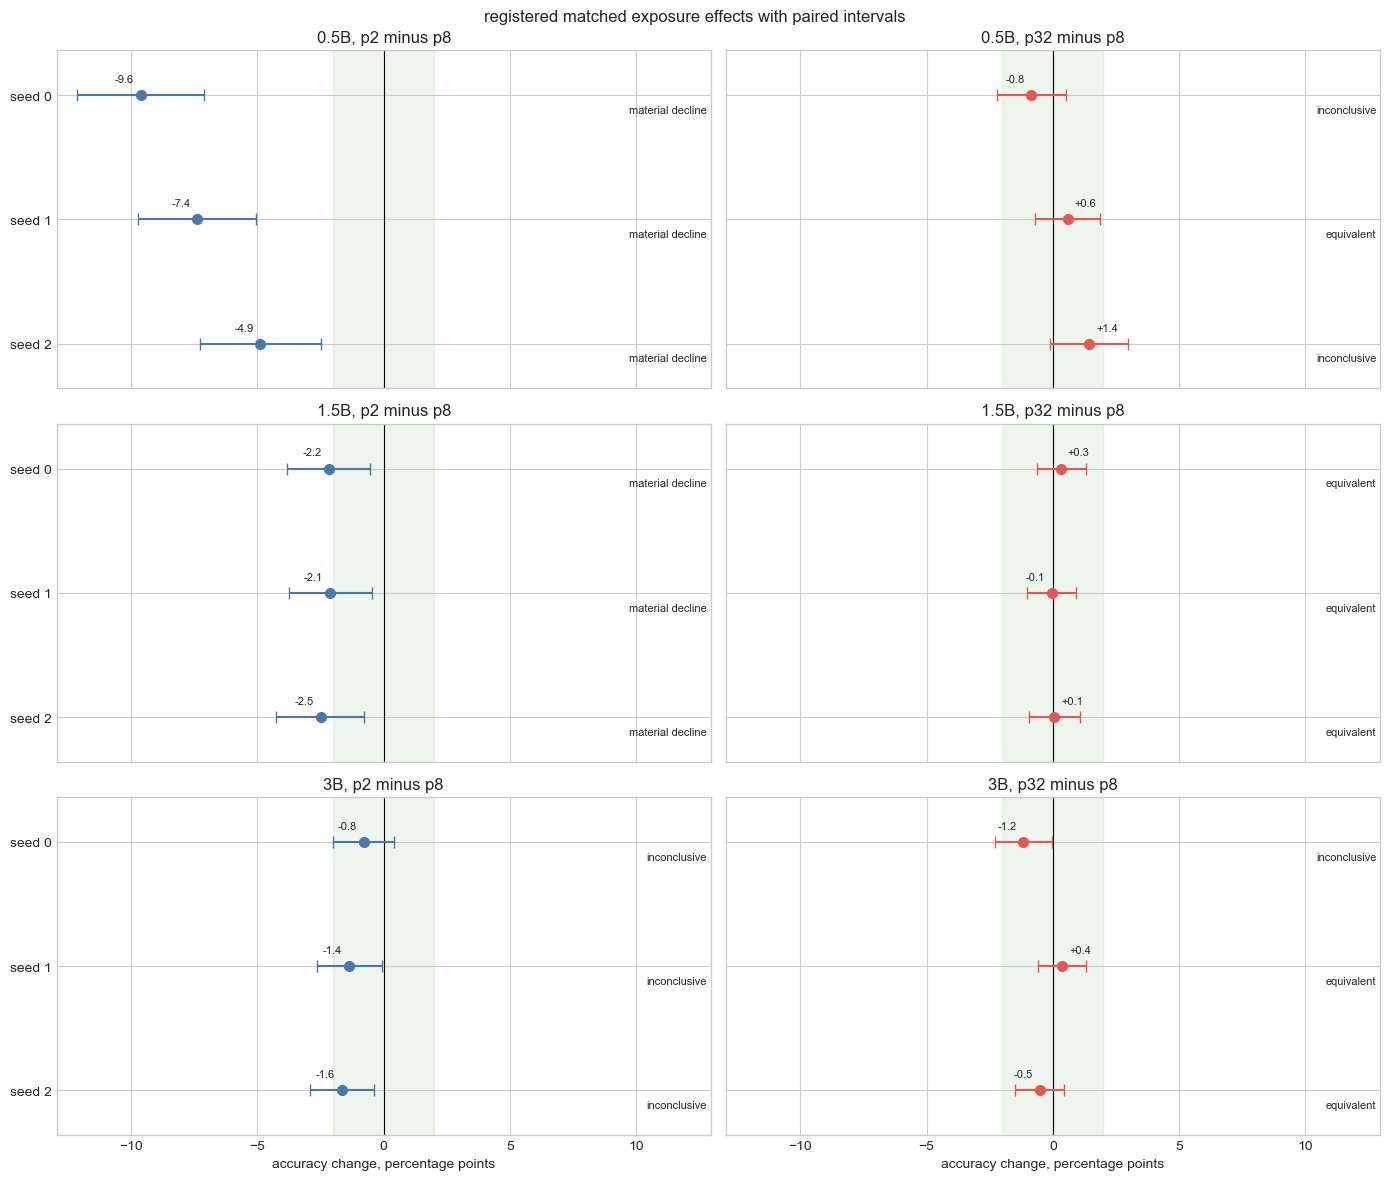

In [5]:
# plot all registered effects on one shared scale
effect_limit = max(
    2.5,
    abs(effect_tbl['ci low'].min()) * 100 + 0.8,
    abs(effect_tbl['ci high'].max()) * 100 + 0.8,
)
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True, sharey=True)
for row_index, scale in enumerate(SCALES):
    for col_index, exposure in enumerate(COMPARISON_EXPOSURES):
        ax = axes[row_index, col_index]
        table = effect_tbl.query(
            'scale == @scale and exposure == @exposure'
        ).sort_values('seed')
        y = np.arange(len(table))
        values = table['delta'].to_numpy() * 100
        errors = np.vstack([
            values - table['ci low'].to_numpy() * 100,
            table['ci high'].to_numpy() * 100 - values,
        ])
        ax.axvspan(-2, 2, color='#B9D8B4', alpha=0.25)
        ax.axvline(0, color='black', lw=0.8)
        ax.errorbar(
            values,
            y,
            xerr=errors,
            fmt='o',
            capsize=4,
            color=COLORS[exposure],
            markersize=7,
        )
        for position, (_, value) in zip(y, table.iterrows()):
            ax.annotate(
                value['classification'], (effect_limit - 0.15, position), xytext=(0, -7),
                textcoords='offset points', ha='right', va='top', fontsize=8,
            )
            ax.annotate(
                f"{value['delta'] * 100:+.1f}", (value['delta'] * 100, position), xytext=(5 if value['delta'] >= 0 else -5, 8),
                textcoords='offset points', ha='left' if value['delta'] >= 0 else 'right',
                va='bottom', fontsize=8,
            )
        ax.margins(y=0.18)
        ax.set_yticks(y)
        ax.set_yticklabels([f'seed {seed}' for seed in table['seed']])
        ax.set_xlim(-effect_limit, effect_limit)
        ax.set_title(f'{scale}, {exposure} minus p8')

for ax in axes[-1]:
    ax.set_xlabel('accuracy change, percentage points')
axes[0, 0].invert_yaxis()
fig.suptitle('registered matched exposure effects with paired intervals')
fig.tight_layout()
save(fig, 'fig02_registered_effects')
plt.show()


saved fig03_matched_endpoints


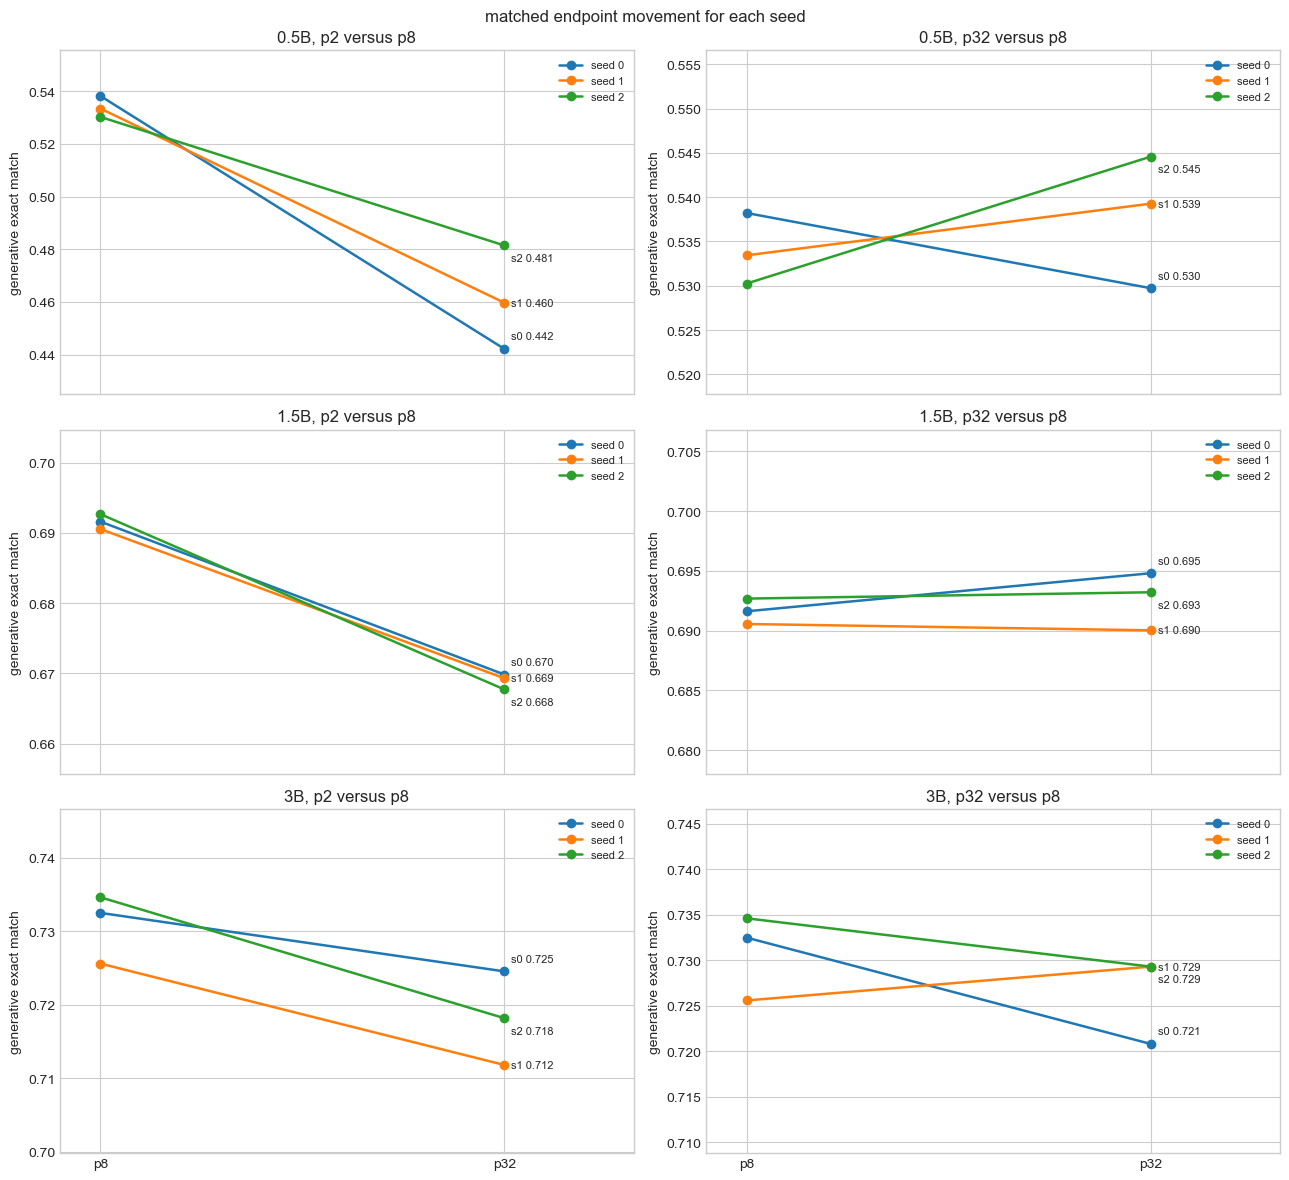

In [6]:
# show each seed moving from p8 to the matched exposure endpoint
fig, axes = plt.subplots(3, 2, figsize=(13, 12), sharex=True)
for row_index, scale in enumerate(SCALES):
    for col_index, exposure in enumerate(COMPARISON_EXPOSURES):
        ax = axes[row_index, col_index]
        values_here = []
        for seed in SEEDS:
            reference = endpoint_tbl.query(
                'scale == @scale and exposure == "p8" and seed == @seed'
            )['overall generative'].iloc[0]
            new = endpoint_tbl.query(
                'scale == @scale and exposure == @exposure and seed == @seed'
            )['overall generative'].iloc[0]
            values_here.extend([reference, new])
            ax.plot(
                [0, 1],
                [reference, new],
                marker='o',
                lw=1.8,
                label=f'seed {seed}',
            )
            ax.annotate(
                f's{seed} {new:.3f}',
                xy=(1, new),
                xytext=(5, (1 - seed) * 9),
                textcoords='offset points',
                va='center',
                fontsize=8,
            )
        padding = max(0.012, (max(values_here) - min(values_here)) * 0.18)
        ax.set_ylim(min(values_here) - padding, max(values_here) + padding)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['p8', exposure])
        ax.set_xlim(-0.1, 1.32)
        ax.set_ylabel('generative exact match')
        ax.set_title(f'{scale}, {exposure} versus p8')
        ax.legend(fontsize=8, loc='best')

fig.suptitle('matched endpoint movement for each seed')
fig.tight_layout()
save(fig, 'fig03_matched_endpoints')
plt.show()


## 4. Effect pattern across scale

The mean effects below are descriptive summaries of the three registered seed-level tests. The vertical ranges show the smallest and largest seed effect, not confidence intervals.


mean     min     max
scale exposure                        
0.5B  p2       -0.0729 -0.0961 -0.0488
      p32       0.0039 -0.0085  0.0143
1.5B  p2       -0.0226 -0.0249 -0.0212
      p32       0.0011 -0.0005  0.0032
3B    p2       -0.0127 -0.0165 -0.0080
      p32      -0.0044 -0.0117  0.0037

saved fig04_effects_across_scale


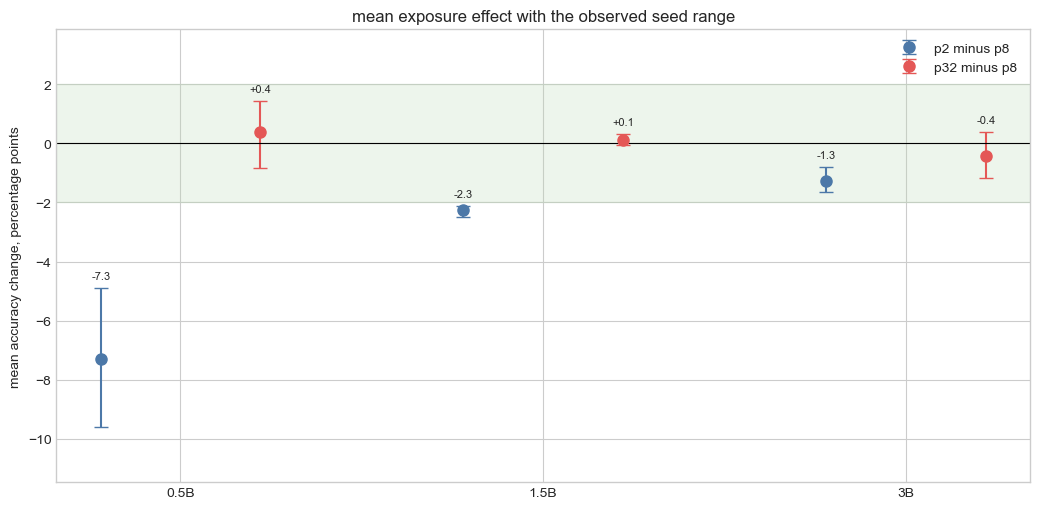

In [7]:
# compare the size and seed spread of each exposure effect
effect_summary = (
    effect_tbl.groupby(['scale', 'exposure'])['delta']
    .agg(['mean', 'min', 'max'])
    .reset_index()
)
display(effect_summary.set_index(['scale', 'exposure']).round(4))

fig, ax = plt.subplots(figsize=(10.5, 5.2))
x = np.arange(len(SCALES))
width = 0.22
for offset, exposure in zip([-width, width], COMPARISON_EXPOSURES):
    table = (
        effect_summary[effect_summary['exposure'] == exposure]
        .set_index('scale')
        .loc[list(SCALES)]
    )
    values = table['mean'].to_numpy() * 100
    errors = np.vstack([
        values - table['min'].to_numpy() * 100,
        table['max'].to_numpy() * 100 - values,
    ])
    ax.errorbar(
        x + offset,
        values,
        yerr=errors,
        fmt='o',
        capsize=5,
        markersize=8,
        color=COLORS[exposure],
        label=f'{exposure} minus p8',
    )
    for position, value, high in zip(x + offset, values, errors[1]):
        ax.annotate(f'{value:+.1f}', (position, value + high), xytext=(0, 5),
                    textcoords='offset points', ha='center', va='bottom', fontsize=8)
ax.margins(y=0.16)
ax.axhspan(-2, 2, color='#B9D8B4', alpha=0.25)
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(SCALES)
ax.set_ylabel('mean accuracy change, percentage points')
ax.set_title('mean exposure effect with the observed seed range')
ax.legend()
fig.tight_layout()
save(fig, 'fig04_effects_across_scale')
plt.show()


## 5. Tier pattern

The heatmap keeps all registered seed-level contrasts visible. A common overall score can hide different movement across easy, medium and hard subjects.


saved fig05_tier_effects


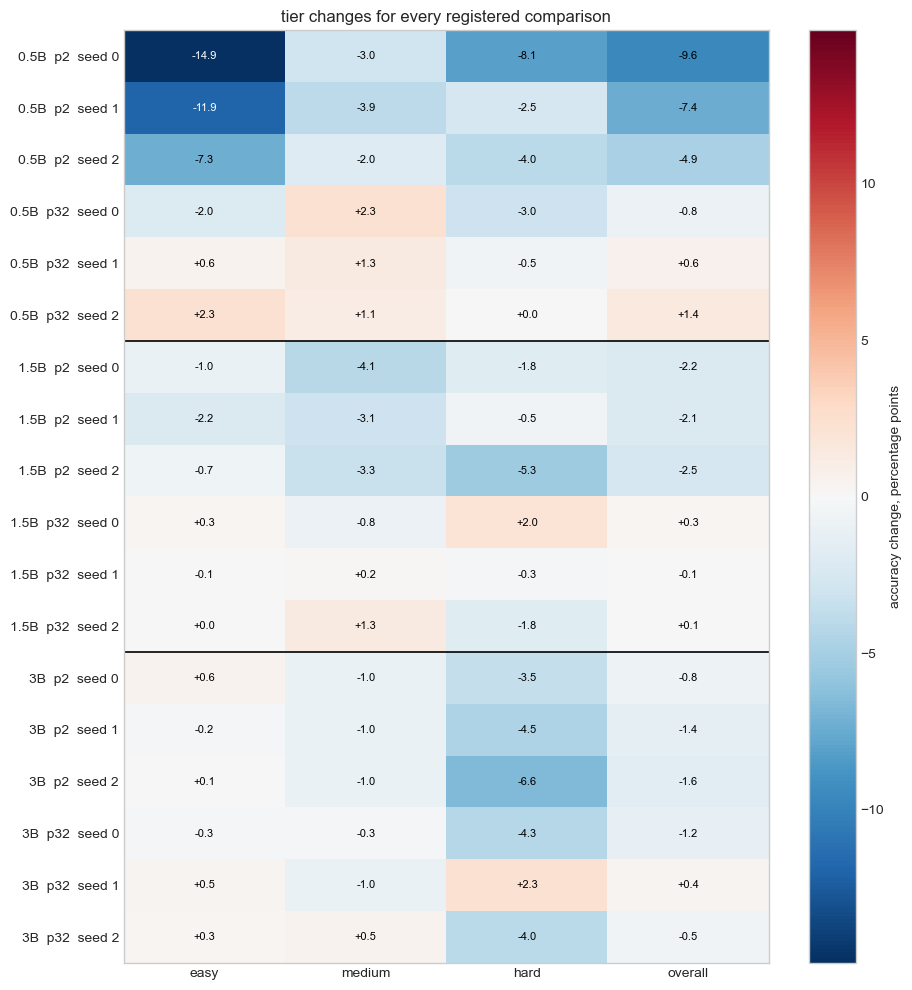

In [8]:
# locate each registered effect across the validated tiers
tier_rows = []
for scale in SCALES:
    for exposure in COMPARISON_EXPOSURES:
        for seed in SEEDS:
            new_data = RUNS[scale][exposure][seed]
            reference_data = RUNS[scale]['p8'][seed]
            for tier in TIERS:
                tier_rows.append({
                    'scale': scale,
                    'comparison': f'{exposure} minus p8',
                    'seed': seed,
                    'group': tier,
                    'delta': (
                        new_data['eval']['per_tier_acc'][tier]
                        - reference_data['eval']['per_tier_acc'][tier]
                    ),
                })
            tier_rows.append({
                'scale': scale,
                'comparison': f'{exposure} minus p8',
                'seed': seed,
                'group': 'overall',
                'delta': (
                    accuracy(new_data['preds'])
                    - accuracy(reference_data['preds'])
                ),
            })
tier_tbl = pd.DataFrame(tier_rows)
tier_order = [
    (scale, f'{exposure} minus p8', seed)
    for scale in SCALES
    for exposure in COMPARISON_EXPOSURES
    for seed in SEEDS
]
tier_matrix = (
    tier_tbl.pivot_table(
        index=['scale', 'comparison', 'seed'],
        columns='group',
        values='delta',
    )
    .loc[tier_order, list(GROUPS)]
    .to_numpy() * 100
)
tier_limit = max(abs(tier_matrix.min()), abs(tier_matrix.max()))

fig, ax = plt.subplots(figsize=(9.5, 10))
image = ax.imshow(
    tier_matrix,
    cmap='RdBu_r',
    norm=TwoSlopeNorm(vmin=-tier_limit, vcenter=0, vmax=tier_limit),
    aspect='auto',
    interpolation='nearest',
)
ax.grid(False)
for row in range(tier_matrix.shape[0]):
    for col in range(tier_matrix.shape[1]):
        color = heatmap_text_color(image, tier_matrix[row, col])
        ax.text(
            col,
            row,
            f'{tier_matrix[row, col]:+.1f}',
            ha='center',
            va='center',
            color=color,
            fontsize=8,
        )
ax.set_xticks(np.arange(len(GROUPS)))
ax.set_xticklabels(GROUPS)
ax.set_yticks(np.arange(len(tier_order)))
ax.set_yticklabels([
    f'{scale}  {comparison.split()[0]}  seed {seed}'
    for scale, comparison, seed in tier_order
])
for boundary in [5.5, 11.5]:
    ax.axhline(boundary, color='black', lw=1.2)
fig.colorbar(image, ax=ax, label='accuracy change, percentage points')
ax.set_title('tier changes for every registered comparison')
fig.tight_layout()
save(fig, 'fig05_tier_effects')
plt.show()


## 6. Subject pattern

Each cell is the mean change across three seeds. Tier separators follow the validated subject mapping. These subject values are descriptive because the registered tests are defined on the full evaluation set.


saved fig06_subject_effects


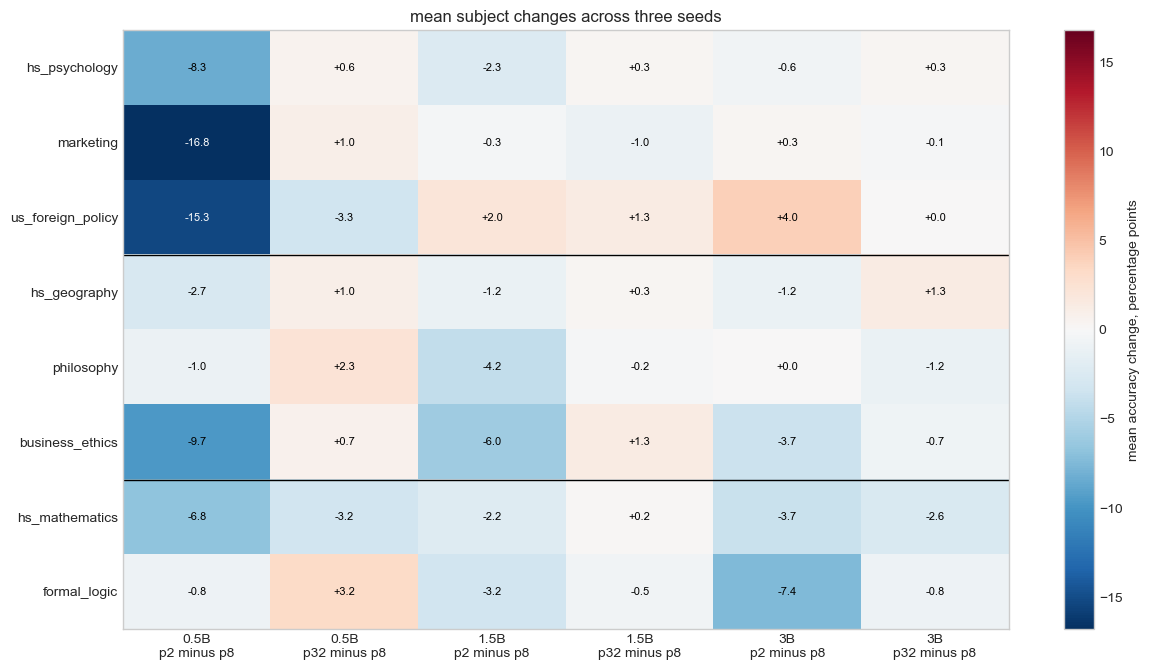

scale                             0.5B            1.5B              3B        
exposure                            p2     p32      p2     p32      p2     p32
tier   subject                                                                
easy   high_school_psychology  -0.0832  0.0061 -0.0232  0.0031 -0.0061  0.0031
       marketing               -0.1681  0.0100 -0.0028 -0.0100  0.0028 -0.0014
       us_foreign_policy       -0.1533 -0.0333  0.0200  0.0133  0.0400  0.0000
hard   formal_logic            -0.0079  0.0317 -0.0317 -0.0053 -0.0741 -0.0079
       high_school_mathematics -0.0679 -0.0321 -0.0222  0.0025 -0.0370 -0.0259
medium business_ethics         -0.0967  0.0067 -0.0600  0.0133 -0.0367 -0.0067
       high_school_geography   -0.0269  0.0101 -0.0118  0.0034 -0.0118  0.0135
       philosophy              -0.0096  0.0225 -0.0418 -0.0021  0.0000 -0.0118

In [9]:
# compare the mean subject changes across scale and exposure
subject_rows = []
for scale in SCALES:
    for exposure in COMPARISON_EXPOSURES:
        for seed in SEEDS:
            for subject in SUBJECTS:
                subject_rows.append({
                    'scale': scale,
                    'exposure': exposure,
                    'seed': seed,
                    'subject': subject,
                    'tier': TIER_LOOKUP[subject],
                    'delta': (
                        RUNS[scale][exposure][seed]['eval']['per_subject_acc'][subject]
                        - RUNS[scale]['p8'][seed]['eval']['per_subject_acc'][subject]
                    ),
                })
subject_tbl = pd.DataFrame(subject_rows)
subject_mean_tbl = (
    subject_tbl.groupby(['scale', 'exposure', 'subject', 'tier'], as_index=False)['delta']
    .mean()
)
subject_columns = [
    (scale, exposure)
    for scale in SCALES
    for exposure in COMPARISON_EXPOSURES
]
subject_matrix = (
    subject_mean_tbl.pivot_table(
        index='subject',
        columns=['scale', 'exposure'],
        values='delta',
    )
    .loc[SUBJECTS, subject_columns]
    .to_numpy() * 100
)
subject_limit = max(abs(subject_matrix.min()), abs(subject_matrix.max()))

fig, ax = plt.subplots(figsize=(12.5, 6.8))
image = ax.imshow(
    subject_matrix,
    cmap='RdBu_r',
    norm=TwoSlopeNorm(vmin=-subject_limit, vcenter=0, vmax=subject_limit),
    aspect='auto',
    interpolation='nearest',
)
ax.grid(False)
for row in range(subject_matrix.shape[0]):
    for col in range(subject_matrix.shape[1]):
        color = heatmap_text_color(image, subject_matrix[row, col])
        ax.text(
            col,
            row,
            f'{subject_matrix[row, col]:+.1f}',
            ha='center',
            va='center',
            color=color,
            fontsize=8,
        )
ax.set_xticks(np.arange(len(subject_columns)))
ax.set_xticklabels([
    f'{scale}\n{exposure} minus p8'
    for scale, exposure in subject_columns
])
ax.set_yticks(np.arange(len(SUBJECTS)))
ax.set_yticklabels([
    subject.replace('high_school_', 'hs_')
    for subject in SUBJECTS
])
easy_end = len(VALIDATED_TIERS['easy']) - 0.5
medium_end = len(VALIDATED_TIERS['easy']) + len(VALIDATED_TIERS['medium']) - 0.5
ax.axhline(easy_end, color='black', lw=1)
ax.axhline(medium_end, color='black', lw=1)
fig.colorbar(image, ax=ax, label='mean accuracy change, percentage points')
ax.set_title('mean subject changes across three seeds')
fig.tight_layout()
save(fig, 'fig06_subject_effects')
plt.show()

display(
    subject_mean_tbl.pivot_table(
        index=['tier', 'subject'],
        columns=['scale', 'exposure'],
        values='delta',
    ).round(4)
)


## 7. Paired item changes

The net score can hide many questions changing in both directions. These panels count items answered correctly only by p8 and items answered correctly only by the comparison exposure.


exposure  reference only correct  new only correct  \
scale comparison   seed                                                      
0.5B  p2 minus p8  0          p2                     392               211   
                   1          p2                     329               190   
                   2          p2                     319               227   
      p32 minus p8 0         p32                     100                84   
                   1         p32                      69                80   
                   2         p32                      96               123   
1.5B  p2 minus p8  0          p2                     144               103   
                   1          p2                     144               104   
                   2          p2                     164               117   
      p32 minus p8 0         p32                      41                47   
                   1         p32                      45                44   
                   2         p32                      47                48   
3B    p2 minus p8  0          p2                      78                63   
                   1          p2                      90                64   
                   2          p2                      90                59   
      p32 minus p8 0         p32                      70                48   
                   1         p32                      40                47   
                   2         p32                      47                37   

                         net items  
scale comparison   seed             
0.5B  p2 minus p8  0          -181  
                   1          -139  
                   2           -92  
      p32 minus p8 0           -16  
                   1            11  
                   2            27  
1.5B  p2 minus p8  0           -41  
                   1           -40  
                   2           -47  
      p32 minus p8 0             6  
                   1            -1  
                   2             1  
3B    p2 minus p8  0           -15  
                   1           -26  
                   2           -31  
      p32 minus p8 0           -22  
                   1             7  
                   2           -10

saved fig07_paired_transitions


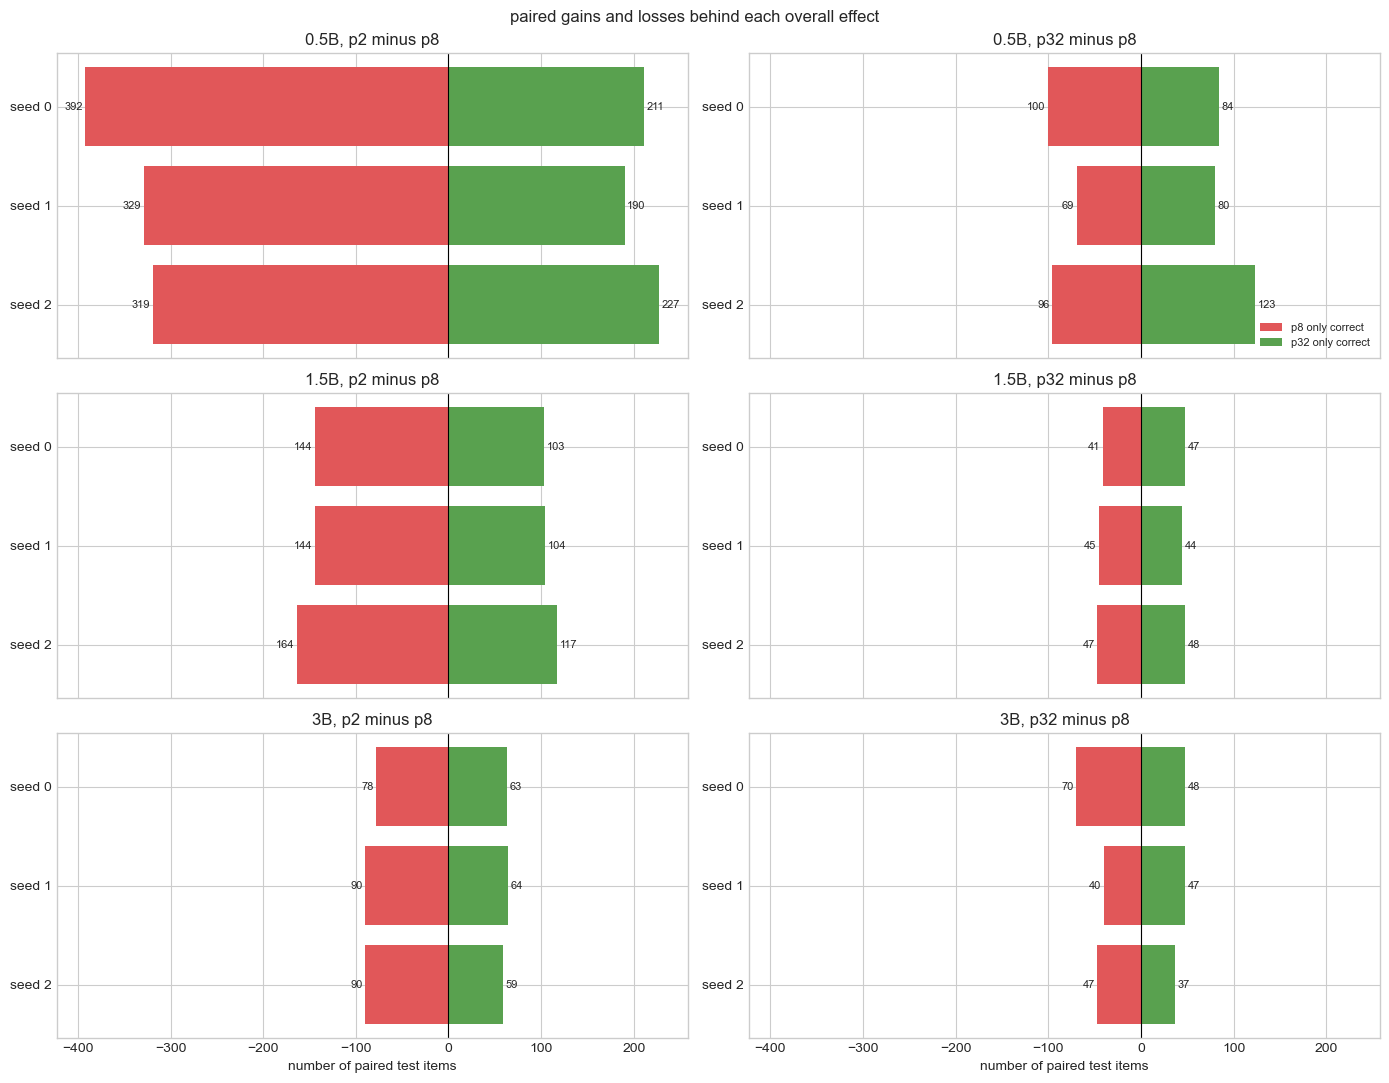

In [10]:
# count paired gains and losses behind the net changes
transition_tbl = effect_tbl[[
    'scale',
    'exposure',
    'comparison',
    'seed',
    'reference only correct',
    'new only correct',
]].copy()
transition_tbl['net items'] = (
    transition_tbl['new only correct']
    - transition_tbl['reference only correct']
)
display(transition_tbl.set_index(['scale', 'comparison', 'seed']))

fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
for row_index, scale in enumerate(SCALES):
    for col_index, exposure in enumerate(COMPARISON_EXPOSURES):
        ax = axes[row_index, col_index]
        table = effect_tbl.query(
            'scale == @scale and exposure == @exposure'
        ).sort_values('seed')
        y = np.arange(len(table))
        losses = -table['reference only correct'].to_numpy()
        gains = table['new only correct'].to_numpy()
        ax.barh(y, losses, color='#E15759', label='p8 only correct')
        ax.barh(y, gains, color='#59A14F', label=f'{exposure} only correct')
        for position, loss, gain in zip(y, -losses, gains):
            ax.text(-loss - 3, position, str(loss), ha='right', va='center', fontsize=8)
            ax.text(gain + 3, position, str(gain), ha='left', va='center', fontsize=8)
        ax.axvline(0, color='black', lw=0.8)
        ax.set_yticks(y)
        ax.set_yticklabels([f'seed {seed}' for seed in table['seed']])
        ax.invert_yaxis()
        ax.set_title(f'{scale}, {exposure} minus p8')
        if row_index == len(SCALES) - 1:
            ax.set_xlabel('number of paired test items')
        if row_index == 0 and col_index == 1:
            ax.legend(fontsize=8, loc='lower right')

fig.suptitle('paired gains and losses behind each overall effect')
fig.tight_layout()
save(fig, 'fig07_paired_transitions')
plt.show()


## 8. Probe and generative behaviour

The letter probe is separate from free generation. A stable probe with a different generative score is evidence about elicitation under this protocol, not proof that factual knowledge was added or removed.


saved fig08_probe_and_generation


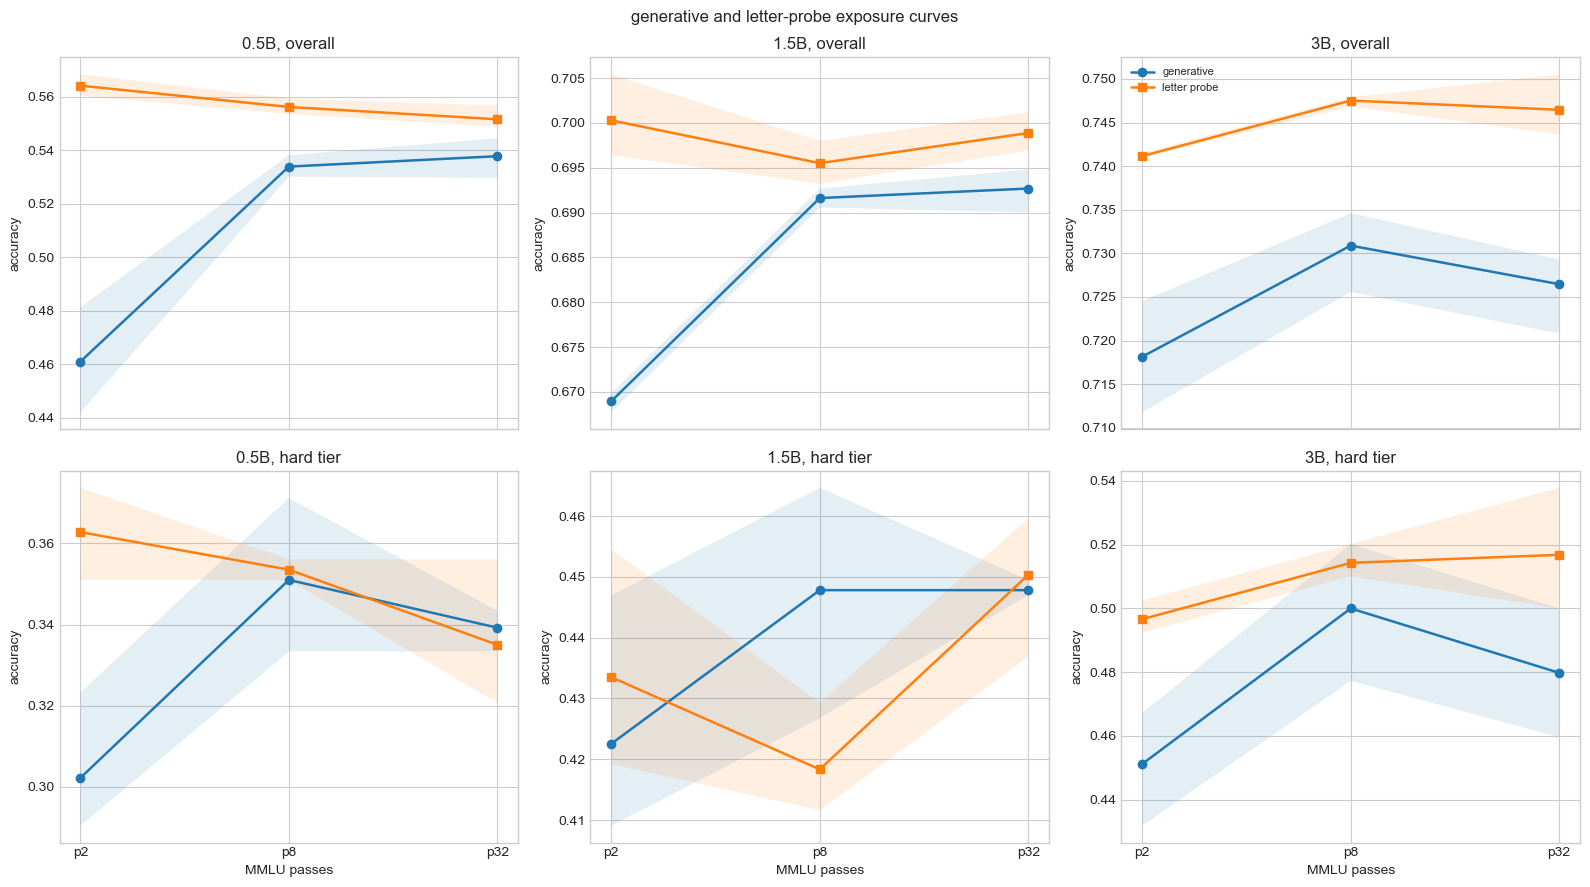

In [11]:
# place the generative and probe curves beside each other
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True)
for col, scale in enumerate(SCALES):
    for row, (generative_metric, probe_metric, title) in enumerate([
        ('overall generative', 'overall probe', 'overall'),
        ('hard generative', 'hard probe', 'hard tier'),
    ]):
        ax = axes[row, col]
        for metric, label, marker in [
            (generative_metric, 'generative', 'o'),
            (probe_metric, 'letter probe', 's'),
        ]:
            means = []
            minimums = []
            maximums = []
            for exposure in EXPOSURES:
                values = endpoint_tbl.query(
                    'scale == @scale and exposure == @exposure'
                )[metric].to_numpy()
                means.append(values.mean())
                minimums.append(values.min())
                maximums.append(values.max())
            x = np.asarray([PASSES[value] for value in EXPOSURES])
            means = np.asarray(means)
            ax.plot(
                x,
                means,
                marker=marker,
                lw=1.8,
                label=label,
            )
            ax.fill_between(
                x,
                minimums,
                maximums,
                alpha=0.12,
            )
        ax.set_xscale('log', base=2)
        ax.set_xticks([2, 8, 32])
        ax.set_xticklabels(['p2', 'p8', 'p32'])
        ax.set_ylabel('accuracy')
        ax.set_title(f'{scale}, {title}')
        if row == 1:
            ax.set_xlabel('MMLU passes')
        if row == 0 and col == 2:
            ax.legend(fontsize=8)

fig.suptitle('generative and letter-probe exposure curves')
fig.tight_layout()
save(fig, 'fig08_probe_and_generation')
plt.show()


## 9. Was seed 0 representative?

This is the descriptive hardening check that motivated experiment 027. It compares the previously reported seed-0 endpoint with the new three-seed mean. A filled marker means the mean moved by at least the standing 2 point materiality threshold.


seed 0  three-seed mean  mean minus seed 0  seed spread  \
scale exposure                                                            
0.5B  p2        0.4421           0.4611             0.0189       0.0393   
      p8        0.5382           0.5340            -0.0042       0.0080   
      p32       0.5297           0.5379             0.0081       0.0149   
1.5B  p2        0.6699           0.6690            -0.0009       0.0021   
      p8        0.6916           0.6916            -0.0000       0.0021   
      p32       0.6948           0.6927            -0.0021       0.0048   
3B    p2        0.7245           0.7182            -0.0064       0.0127   
      p8        0.7325           0.7309            -0.0016       0.0090   
      p32       0.7208           0.7265             0.0057       0.0085   

                material change  
scale exposure                   
0.5B  p2                  False  
      p8                  False  
      p32                 False  
1.5B  p2                  False  
      p8                  False  
      p32                 False  
3B    p2                  False  
      p8                  False  
      p32                 False

saved fig09_seed0_representativeness


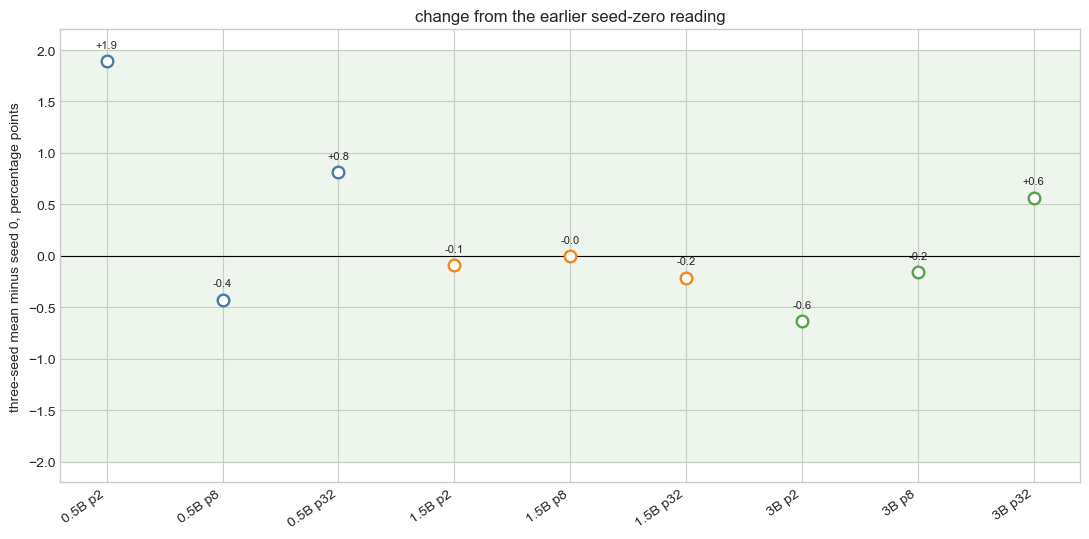

In [12]:
# compare the old seed-zero reading with the complete three-seed mean
representative_rows = []
for item in endpoint_summary:
    representative_rows.append({
        'scale': item['scale'],
        'exposure': item['exposure'],
        'seed 0': item['seed_values']['0'],
        'three-seed mean': item['mean'],
        'mean minus seed 0': item['mean_minus_seed0'],
        'seed spread': item['spread'],
        'material change': item['material_change_from_seed0'],
    })
representative_tbl = pd.DataFrame(representative_rows)
display(representative_tbl.set_index(['scale', 'exposure']).round(4))

fig, ax = plt.subplots(figsize=(11, 5.5))
labels = [
    f"{row['scale']} {row['exposure']}"
    for _, row in representative_tbl.iterrows()
]
x = np.arange(len(representative_tbl))
values = representative_tbl['mean minus seed 0'].to_numpy() * 100
for position, (_, row), value in zip(x, representative_tbl.iterrows(), values):
    face = SCALE_COLORS[row['scale']] if row['material change'] else 'white'
    ax.scatter(
        position,
        value,
        s=70,
        facecolor=face,
        edgecolor=SCALE_COLORS[row['scale']],
        linewidth=1.7,
        zorder=3,
    )
    ax.text(position, value + 0.13, f'{value:+.1f}', ha='center', fontsize=8)
ax.axhspan(-2, 2, color='#B9D8B4', alpha=0.25)
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=35, ha='right')
ax.set_ylabel('three-seed mean minus seed 0, percentage points')
ax.set_title('change from the earlier seed-zero reading')
fig.tight_layout()
save(fig, 'fig09_seed0_representativeness')
plt.show()


## 10. Exact values

The tables below are saved beside the figures so the plotted values can be reused without reading them from the images.


In [13]:
# save the exact values used by the figures
health_tbl.reset_index().to_csv(FIG / '027_1_run_health.csv', index=False)
endpoint_tbl.to_csv(FIG / '027_1_endpoints.csv', index=False)
effect_tbl.to_csv(FIG / '027_1_registered_effects.csv', index=False)
common_tbl.to_csv(FIG / '027_1_common_readings.csv', index=False)
effect_summary.to_csv(FIG / '027_1_effects_across_scale.csv', index=False)
tier_tbl.to_csv(FIG / '027_1_tier_effects.csv', index=False)
subject_tbl.to_csv(FIG / '027_1_subject_effects.csv', index=False)
transition_tbl.to_csv(FIG / '027_1_paired_transitions.csv', index=False)
representative_tbl.to_csv(FIG / '027_1_seed0_representativeness.csv', index=False)

headline = effect_tbl.copy()
for column in ['reference', 'new', 'delta', 'ci low', 'ci high']:
    headline[column] = (headline[column] * 100).round(2)
headline['95% interval'] = headline.apply(
    lambda row: f"[{row['ci low']:+.2f}, {row['ci high']:+.2f}]",
    axis=1,
)
display(headline[[
    'scale',
    'comparison',
    'seed',
    'reference',
    'new',
    'delta',
    '95% interval',
    'Holm p',
    'classification',
]].set_index(['scale', 'comparison', 'seed']))

print('saved exact tables ->', FIG.relative_to(ROOT))


reference    new  delta     95% interval  \
scale comparison   seed                                             
0.5B  p2 minus p8  0         53.82  44.21  -9.61  [-12.15, -7.11]   
                   1         53.34  45.97  -7.38   [-9.71, -5.04]   
                   2         53.03  48.14  -4.88   [-7.27, -2.49]   
      p32 minus p8 0         53.82  52.97  -0.85   [-2.23, +0.53]   
                   1         53.34  53.93   0.58   [-0.69, +1.86]   
                   2         53.03  54.46   1.43   [-0.11, +2.97]   
1.5B  p2 minus p8  0         69.16  66.99  -2.18   [-3.82, -0.53]   
                   1         69.06  66.93  -2.12   [-3.77, -0.48]   
                   2         69.27  66.77  -2.49   [-4.25, -0.80]   
      p32 minus p8 0         69.16  69.48   0.32   [-0.64, +1.33]   
                   1         69.06  69.00  -0.05   [-1.01, +0.90]   
                   2         69.27  69.32   0.05   [-0.96, +1.06]   
3B    p2 minus p8  0         73.25  72.45  -0.80   [-2.02, +0.42]   
                   1         72.56  71.18  -1.38   [-2.65, -0.05]   
                   2         73.46  71.82  -1.65   [-2.92, -0.37]   
      p32 minus p8 0         73.25  72.08  -1.17   [-2.28, -0.05]   
                   1         72.56  72.93   0.37   [-0.58, +1.33]   
                   2         73.46  72.93  -0.53   [-1.49, +0.42]   

                               Holm p    classification  
scale comparison   seed                                  
0.5B  p2 minus p8  0     4.560493e-13  material decline  
                   1     2.214019e-09  material decline  
                   2     9.502870e-05  material decline  
      p32 minus p8 0     5.375197e-01      inconclusive  
                   1     5.375197e-01        equivalent  
                   2     2.360812e-01      inconclusive  
1.5B  p2 minus p8  0     2.155168e-02  material decline  
                   1     2.155168e-02  material decline  
                   2     1.790618e-02  material decline  
      p32 minus p8 0     1.000000e+00        equivalent  
                   1     1.000000e+00        equivalent  
                   2     1.000000e+00        equivalent  
3B    p2 minus p8  0     2.382870e-01      inconclusive  
                   1     8.719987e-02      inconclusive  
                   2     4.113610e-02      inconclusive  
      p32 minus p8 0     1.582450e-01      inconclusive  
                   1     6.522683e-01        equivalent  
                   2     6.522683e-01        equivalent

saved exact tables -> analysis/figures/027_1


## Cross-referenced conclusion

All twelve new evaluations passed the integrity checks. Every identity gate had 100% item agreement, each generative pass contained 1,884 items and the committed prediction and metric hashes matched the manifests.

Seed 0 was reasonably representative of the final means. None of the nine p2, p8 and p32 endpoints moved by the standing 2 point threshold after adding seeds 1 and 2. The largest change was 0.5B p2, where the mean was 1.9 points above seed 0 but still remained far below p8.

At 0.5B, p2 was a material decline from p8 in all three seeds, from -9.6 to -4.9 points. At 1.5B the same result held with a smaller and very stable decline of -2.5 to -2.1 points. The 3B p2 estimates were -1.6 to -0.8 points and all three remained inconclusive after Holm correction. This suggests that the cost of very short MC-SFT exposure becomes smaller as model scale increases, although the 3B family does not establish equivalence.

P32 did not improve clearly over p8 at any scale. The 1.5B comparison was equivalent in all three seeds. The 0.5B and 3B families were mixed because some intervals crossed the equivalence boundary. The hard-tier view adds an important detail: at 3B, p2 was 3.5 to 6.6 points below p8 on hard subjects even though the overall changes stayed below 2 points.

Completed three-seed evidence supports p8 as a strong supervised budget in this grid. It doesn't show a benefit from extending to p32, while p2 is clearly insufficient at 0.5B and 1.5B. These are method-as-practised results because each exposure used its own learning-rate decay schedule.
